# Task 6: Supervised Model Development
**Singularity Research Lab – AI Division**  
**Project:** Electricity Bill Predictor  
**Models:** Linear Regression (Primary) & Decision Tree Regressor (Comparison)  
**Input:** `data/featured_daily_electricity_consumption.csv`  
**Output Artifacts:** `models/linear_regression.joblib`, `models/decision_tree.joblib`, `results/test_predictions.csv`

---

## 1. Executive Summary & Architecture
In this task, we develop two complementary supervised regression models:
1. **Linear Regression (OLS) – Primary Model:** Parametric, transparent, closed-form estimator.
2. **Decision Tree Regressor – Comparison Model:** Non-parametric, recursive partitioning estimator capturing non-linear feature interactions.

**Key Engineering Rules Applied:**
- **Strict Chronological Splitting:** Training data (first 80%) strictly precedes testing data (final 20%) in time.
- **Zero Random Shuffling:** Shuffling is explicitly disabled (`shuffle=False`) to prevent lookahead bias.
- **Reproducibility:** Deterministic seeds (`random_state=42`) and model persistence using `joblib`.
- **Neutrality:** No performance claims are made until formal evaluation in Task 7.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Ensure module import path
sys.path.insert(0, os.path.abspath('..'))
from src.train import (
    split_chronological,
    train_linear_regression,
    train_decision_tree,
    save_model,
    load_model,
    generate_predictions,
    run_training_pipeline,
    FEATURE_COLUMNS,
    TARGET_COLUMN,
)

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)
sns.set_theme(style='whitegrid', font_scale=1.1)

# Ingest feature-engineered dataset
data_path = 'data/featured_daily_electricity_consumption.csv'
if not os.path.exists(data_path):
    data_path = os.path.join('..', 'data', 'featured_daily_electricity_consumption.csv')

df = pd.read_csv(data_path)
print(f"Loaded {len(df):,} records with {len(df.columns)} columns from {data_path}")
print(f"Feature columns: {FEATURE_COLUMNS}")
print(f"Target column:   {TARGET_COLUMN}")


Loaded 1,433 records with 8 columns from data/featured_daily_electricity_consumption.csv
Feature columns: ['Lag_1', 'Lag_7', 'Rolling_Mean_7', 'Day_of_Week', 'Month', 'Is_Weekend']
Target column:   Daily_Energy_kWh


## 2. Chronological Train-Test Partitioning

### Why Chronological Splitting is Mandatory
In time-series and forecasting applications, cross-sectional random splitting (e.g., standard `train_test_split(shuffle=True)`) is fundamentally flawed because it causes **temporal data leakage**. When observations from 2008 are used to predict observations from 2007, the model trains on future states to predict the past.

We enforce a strictly forward-looking chronological partition:
- **Training Set (Earlier 80%):** 1,146 observations spanning **2006-12-24 to 2010-02-11** (~3.13 years).
- **Holdout Test Set (Later 20%):** 287 observations spanning **2010-02-12 to 2010-11-25** (~9.5 months).


In [2]:
split_data = split_chronological(df, feature_cols=FEATURE_COLUMNS, target_col=TARGET_COLUMN, test_size=0.2)

X_train = split_data['X_train']
y_train = split_data['y_train']
X_test = split_data['X_test']
y_test = split_data['y_test']
train_dates = split_data['train_dates']
test_dates = split_data['test_dates']
info = split_data['split_info']

split_summary = pd.DataFrame({
    'Partition': ['Full Dataset', 'Training Set (Earlier)', 'Test Set (Later)'],
    'Record Count': [info['n_total'], info['n_train'], info['n_test']],
    'Percentage': ['100.0%', f"{info['train_ratio']*100:.1f}%", f"{info['test_ratio']*100:.1f}%"],
    'Start Date': [df['Date'].min(), info['train_start_date'], info['test_start_date']],
    'End Date': [df['Date'].max(), info['train_end_date'], info['test_end_date']],
})
print("--- Chronological Partitioning Summary ---")
print(split_summary.to_string(index=False))


--- Chronological Partitioning Summary ---
             Partition  Record Count Percentage Start Date   End Date
          Full Dataset          1433     100.0% 2006-12-24 2010-11-25
Training Set (Earlier)          1146      80.0% 2006-12-24 2010-02-11
      Test Set (Later)           287      20.0% 2010-02-12 2010-11-25


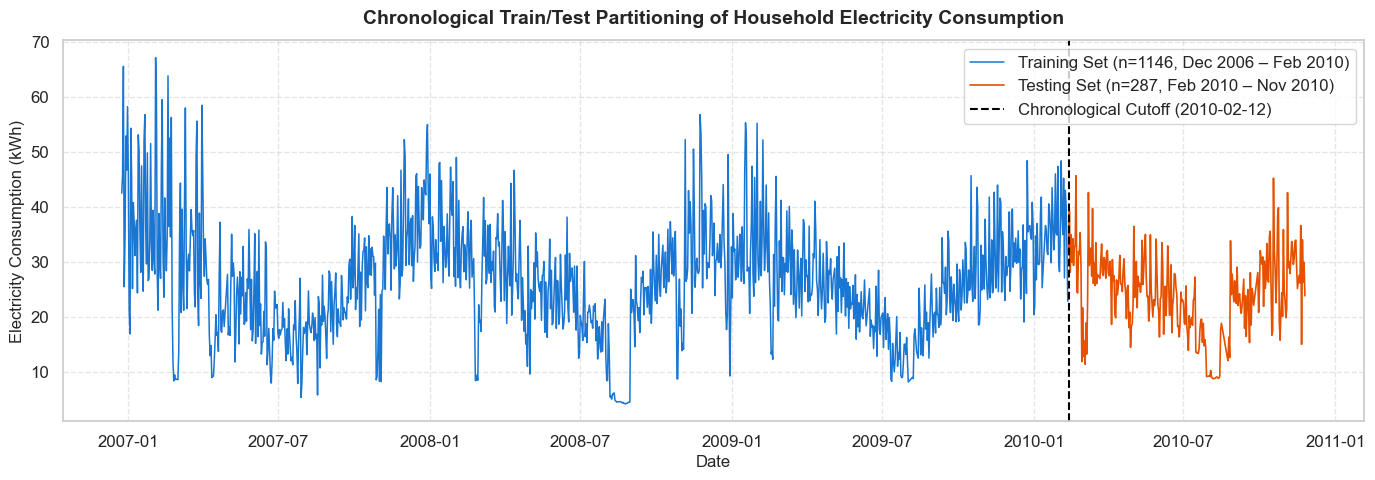

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))

# Plot train and test partitions
df_plot = df.copy()
df_plot['Date'] = pd.to_datetime(df_plot['Date'])

train_mask = df_plot['Date'] <= pd.to_datetime(info['train_end_date'])
test_mask = df_plot['Date'] >= pd.to_datetime(info['test_start_date'])

ax.plot(df_plot.loc[train_mask, 'Date'], df_plot.loc[train_mask, 'Daily_Energy_kWh'], 
        color='#1976d2', linewidth=1.1, label=f"Training Set (n={info['n_train']}, Dec 2006 – Feb 2010)")
ax.plot(df_plot.loc[test_mask, 'Date'], df_plot.loc[test_mask, 'Daily_Energy_kWh'], 
        color='#e65100', linewidth=1.2, label=f"Testing Set (n={info['n_test']}, Feb 2010 – Nov 2010)")

ax.axvline(pd.to_datetime(info['test_start_date']), color='black', linestyle='--', linewidth=1.5, 
           label=f"Chronological Cutoff ({info['test_start_date']})")

ax.set_title('Chronological Train/Test Partitioning of Household Electricity Consumption', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Electricity Consumption (kWh)', fontsize=12)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 3. Model 1: Linear Regression (Primary Model)

### Mathematical Intuition
Linear Regression models the conditional expectation of daily electricity consumption as an affine combination of input regressors:
$$\hat{y} = w_0 + \sum_{j=1}^{p} w_j X_j = \mathbf{X} \mathbf{w}$$

Where:
- $w_0$ represents the intercept (expected baseline consumption when all features are zero).
- $w_j$ represents the marginal change in daily electricity consumption (kWh) associated with a one-unit increase in feature $X_j$, holding all other features fixed.

### Loss Function & Normal Equation
The weights $\mathbf{w}^*$ are determined by Ordinary Least Squares (OLS), minimizing the residual sum of squares:
$$\mathcal{L}(\mathbf{w}) = \| \mathbf{y} - \mathbf{X} \mathbf{w} \|_2^2 = \sum_{i=1}^{n} (y_i - \mathbf{x}_i^T \mathbf{w})^2$$

Setting the gradient $\nabla_{\mathbf{w}} \mathcal{L} = \mathbf{0}$ yields the closed-form normal equations:
$$\mathbf{w}^* = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{y}$$

### Hyperparameters:
- `fit_intercept=True`: Fits the baseline offset $w_0$. Essential because households have continuous non-zero standby loads.


In [4]:
# Fit Linear Regression
lr_model = train_linear_regression(X_train, y_train, fit_intercept=True)

# Save model
models_dir = 'models' if os.path.exists('models') else '../models'
save_model(lr_model, os.path.join(models_dir, 'linear_regression.joblib'))

# Inspect fitted weights
weights_df = pd.DataFrame({
    'Feature': ['Intercept (w0)'] + FEATURE_COLUMNS,
    'Weight (Coefficient)': [lr_model.intercept_] + list(lr_model.coef_)
})
print("--- Fitted Linear Regression Coefficients ---")
print(weights_df.to_string(index=False))


--- Fitted Linear Regression Coefficients ---
       Feature  Weight (Coefficient)
Intercept (w0)                1.4354
         Lag_1                0.2050
         Lag_7                0.0457
Rolling_Mean_7                0.6222
   Day_of_Week                0.1308
         Month                0.0569
    Is_Weekend                4.0109


## 4. Model 2: Decision Tree Regressor (Comparison Model)

### Mathematical Intuition
The Decision Tree Regressor partitions the 6-dimensional feature space into $M$ disjoint orthogonal hyper-rectangles $R_1, R_2, \dots, R_M$.
For any test vector $\mathbf{x} \in R_m$, the predicted consumption is the empirical average of all training points that landed in that region:
$$\hat{y}(\mathbf{x}) = \frac{1}{|R_m|} \sum_{i \in R_m} y_i$$

### Splitting Criterion (Greedy Variance Reduction)
At each internal decision node, the algorithm evaluates all candidate features $j$ and split thresholds $s$ to find the split that minimizes the sum of squared errors across children partitions:
$$\arg\min_{j, s} \left[ \sum_{i \in R_1(j, s)} (y_i - \bar{y}_{R_1})^2 + \sum_{i \in R_2(j, s)} (y_i - \bar{y}_{R_2})^2 \right]$$

### Hyperparameters and Regularization Rationale:
1. `max_depth=5`: Bounds the tree depth to 5 split levels ($2^5 = 32$ terminal leaves maximum). Prevents the tree from memorizing individual days and overfitting high-frequency noise.
2. `min_samples_split=10`: Requires at least 10 historical days before attempting a partition.
3. `min_samples_leaf=5`: Requires that every leaf region contains at least 5 days, ensuring the leaf mean is statistically robust.
4. `random_state=42`: Fixes deterministic split selection when ties occur across features.


In [5]:
# Fit Decision Tree Regressor
dt_model = train_decision_tree(
    X_train,
    y_train,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Save model
save_model(dt_model, os.path.join(models_dir, 'decision_tree.joblib'))

# Feature importance table
importance_df = pd.DataFrame({
    'Feature': FEATURE_COLUMNS,
    'Gini Importance (Variance Reduction)': dt_model.feature_importances_
}).sort_values('Gini Importance (Variance Reduction)', ascending=False)

print("--- Decision Tree Regressor Feature Importances ---")
print(importance_df.to_string(index=False))


--- Decision Tree Regressor Feature Importances ---
       Feature  Gini Importance (Variance Reduction)
Rolling_Mean_7                                0.6983
         Lag_1                                0.1513
    Is_Weekend                                0.0845
         Month                                0.0413
         Lag_7                                0.0127
   Day_of_Week                                0.0118


## 5. Test Set Predictions Generation
We generate point predictions on the 287 out-of-time test days (`2010-02-12` to `2010-11-25`) using both trained models.
Predictions are recorded alongside actual consumption values for downstream evaluation.


In [6]:
# Generate predictions
y_pred_lr = generate_predictions(lr_model, X_test)
y_pred_dt = generate_predictions(dt_model, X_test)

# Build predictions dataframe
test_results_df = pd.DataFrame({
    'Date': test_dates.dt.strftime('%Y-%m-%d'),
    'Actual_Daily_Energy_kWh': y_test.values,
    'Pred_Linear_Regression': y_pred_lr,
    'Pred_Decision_Tree': y_pred_dt,
})

# Save predictions table
results_dir = 'results' if os.path.exists('results') else '../results'
pred_csv_path = os.path.join(results_dir, 'test_predictions.csv')
test_results_df.to_csv(pred_csv_path, index=False)
print(f"Saved test predictions table to: {pred_csv_path} ({len(test_results_df)} rows)")

print("\nFirst 5 Test Predictions:")
print(test_results_df.head(5).to_string(index=False))

print("\nLast 5 Test Predictions:")
print(test_results_df.tail(5).to_string(index=False))


Saved test predictions table to: results/test_predictions.csv (287 rows)

First 5 Test Predictions:
      Date  Actual_Daily_Energy_kWh  Pred_Linear_Regression  Pred_Decision_Tree
2010-02-12                  31.5500                 30.2170             34.3184
2010-02-13                  39.1926                 36.3097             40.1515
2010-02-14                  28.1417                 36.6435             40.1515
2010-02-15                  34.9522                 30.4038             29.9549
2010-02-16                  29.9626                 31.0894             29.9549

Last 5 Test Predictions:
      Date  Actual_Daily_Energy_kWh  Pred_Linear_Regression  Pred_Decision_Tree
2010-11-21                  15.0152                 34.1355             28.7157
2010-11-22                  34.0256                 23.0037             10.1592
2010-11-23                  26.2923                 27.2870             26.5652
2010-11-24                  29.9375                 25.9877             26

## 6. Visual Overview of Out-of-Time Predictions
We plot both model predictions against actual test consumption across the 287-day test horizon.
*(Note: Full quantitative error evaluation and model ranking will be performed formally in Task 7).*


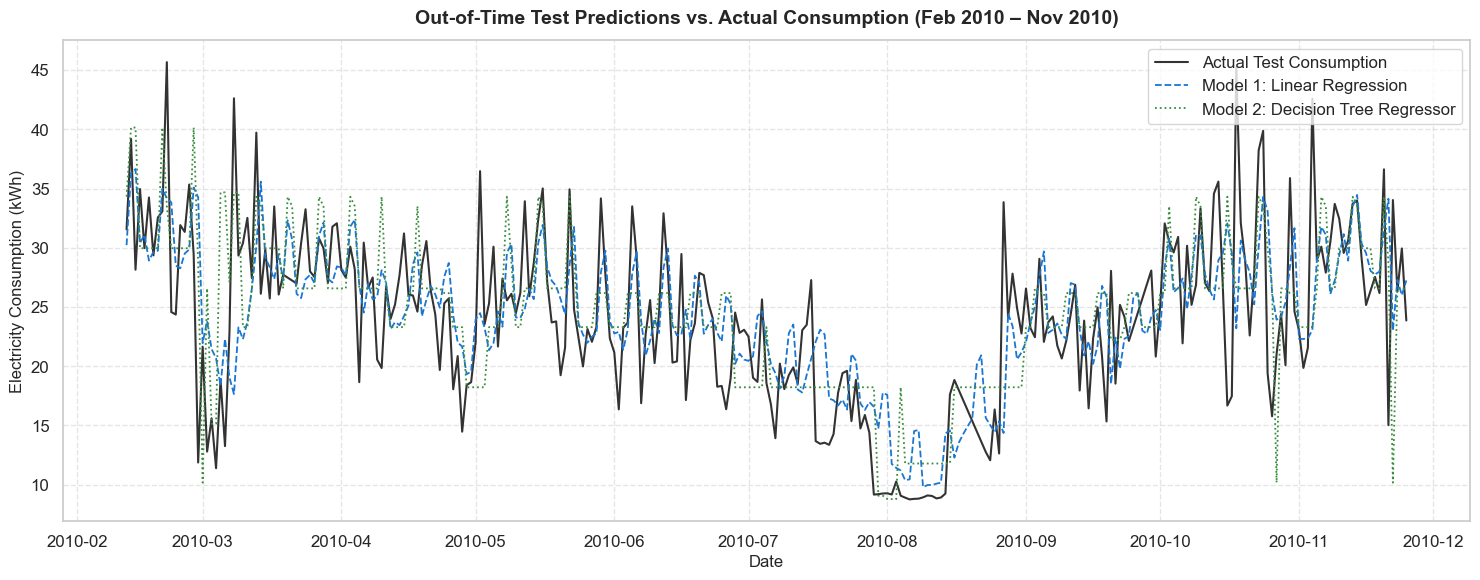

In [7]:
fig, ax = plt.subplots(figsize=(15, 6))

test_results_df['Plot_Date'] = pd.to_datetime(test_results_df['Date'])

ax.plot(test_results_df['Plot_Date'], test_results_df['Actual_Daily_Energy_kWh'], 
        color='black', linewidth=1.5, alpha=0.8, label='Actual Test Consumption')
ax.plot(test_results_df['Plot_Date'], test_results_df['Pred_Linear_Regression'], 
        color='#1976d2', linewidth=1.3, linestyle='--', label='Model 1: Linear Regression')
ax.plot(test_results_df['Plot_Date'], test_results_df['Pred_Decision_Tree'], 
        color='#388e3c', linewidth=1.3, linestyle=':', label='Model 2: Decision Tree Regressor')

ax.set_title('Out-of-Time Test Predictions vs. Actual Consumption (Feb 2010 – Nov 2010)', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Date', fontsize=12)
ax.set_ylabel('Electricity Consumption (kWh)', fontsize=12)
ax.legend(loc='upper right', frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 7. Summary of Task 6 Outcomes
- **Chronological Split:** Strictly forward-looking (80% train = 1,146 days; 20% test = 287 days) with zero random shuffling.
- **Model 1 (Linear Regression):** Trained via OLS normal equation; weights reflect continuous additive contributions.
- **Model 2 (Decision Tree Regressor):** Trained with depth regularization (`max_depth=5`, `min_samples_leaf=5`, `random_state=42`) to prevent memorization.
- **Artifacts Persisted:**
  - `models/linear_regression.joblib`
  - `models/decision_tree.joblib`
  - `results/test_predictions.csv`
- **Modular Pipeline:** [`src/train.py`](../src/train.py).
